# Hilbert Sorting, `SnapIndex`, and `GeoKDTree`

To snap a coordinate `(latitude, longitude)` to its nearest graph node, `scgraph` supports two spatial indexes with the same query interface:

- **`SnapIndex`** (`scgraph`): an 8-way bounding-box index (fast C++ with pure-Python fallback) that reads node coordinates directly in place without rearranging them. To keep queries fast, nearby points should sit near each other in memory—for example, sorted along a **Hilbert curve**.
- **`GeoKDTree`** (`geokdtree`): a 3D spherical KD-tree that builds its own tree in memory from points in any order.

This example shows how to:
1. **Sort 1,000 scattered points** across the planet using `hilbert_order` and plot the resulting path.
2. **Build and query `GeoKDTree` and `SnapIndex`** (and see why `SnapIndex` expects Hilbert order).
3. **Verify equivalence** between both indexes, standalone and inside `GeoGraph`.
4. **Compare performance** in mid-latitudes, high latitudes, and near the antimeridian (`±180°`).


In [1]:
# Optional libraries used for plotting in this notebook:
# !pip install scgraph matplotlib folium

from array import array
import math
import random
import time

import folium
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from geokdtree import GeoKDTree

from scgraph import GeoGraph
from scgraph.helpers.hilbert import hilbert_key, hilbert_order
from scgraph.utils import haversine, has_cpp

try:
    from scgraph.cpp import NodeOrderError, SnapIndex
except ImportError:
    from scgraph.helpers.snap_index import NodeOrderError, SnapIndex

print(f"scgraph C++ backend enabled: {has_cpp()}")


scgraph C++ backend enabled: True


## 1. Sorting 1,000 Scattered Points Along a Hilbert Curve

`hilbert_key(latitude, longitude)` maps a geographic coordinate onto a 65,536 × 65,536 grid (`CURVE_ORDER = 16`, about 600 m × 300 m per cell at the equator) and returns its 1D position along a space-filling Hilbert curve.
`hilbert_order(points)` returns the index order that visits those points along the curve.

Let's sample 1,000 points evenly over the globe and compare the path connecting them before and after sorting.


In [2]:
rng = random.Random(42)

# Sample 1,000 points uniformly on the sphere
points = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(1000)
]

order = hilbert_order(points)
ordered_points = [points[i] for i in order]

raw_km = sum(haversine(a, b) for a, b in zip(points, points[1:]))
hilbert_km = sum(
    haversine(a, b) for a, b in zip(ordered_points, ordered_points[1:])
)

print(f"Points sampled        : {len(points):,}")
print(f"First Hilbert key     : {hilbert_key(*ordered_points[0]):,}")
print(f"Random path length    : {raw_km:,.0f} km")
print(
    f"Hilbert path length   : {hilbert_km:,.0f} km ({raw_km / hilbert_km:.1f}x shorter)"
)


Points sampled        : 1,000
First Hilbert key     : 52,438,812
Random path length    : 9,920,774 km
Hilbert path length   : 728,888 km (13.6x shorter)


### Visualizing the Path Formed Around the Planet

On a flat world map, a line crossing the antimeridian (`±180°` longitude) would otherwise stretch horizontally across the whole figure. A small helper splits segments wherever `abs(lon_b - lon_a) > 180` so both static and interactive maps stay clean.


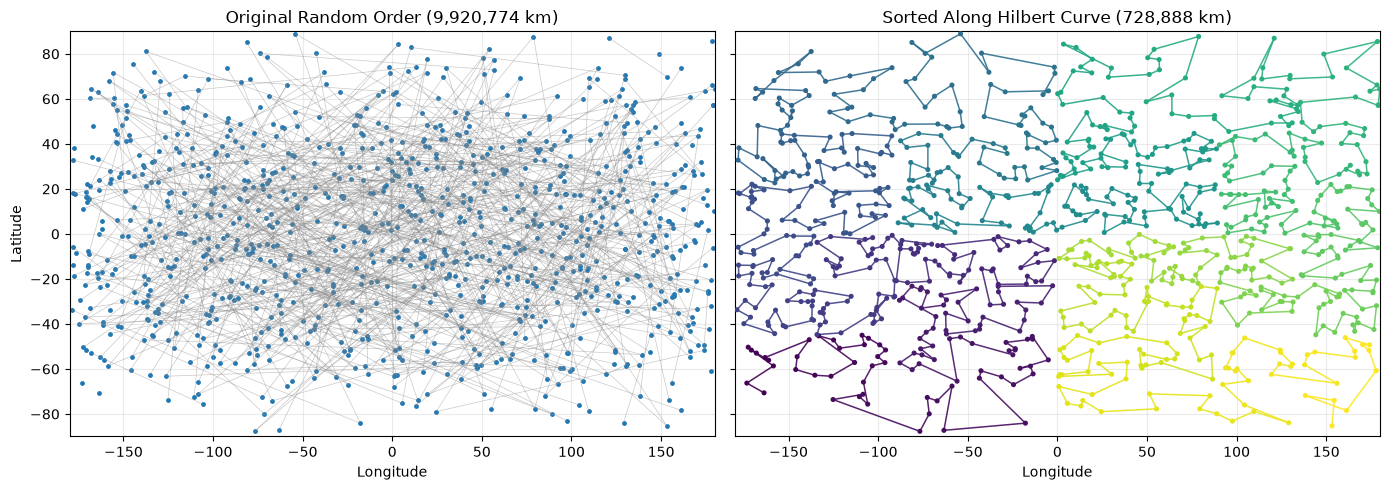

In [3]:
def antimeridian_segments(coords):
    """Return (segment, point_index) pairs, skipping jumps across ±180 deg."""
    segments, indices = [], []
    for i, (a, b) in enumerate(zip(coords, coords[1:])):
        if abs(b[1] - a[1]) <= 180:
            segments.append([(a[1], a[0]), (b[1], b[0])])
            indices.append(i)
    return segments, indices


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# Left: original random order
raw_segs, _ = antimeridian_segments(points)
axes[0].add_collection(
    LineCollection(raw_segs, colors="#888888", linewidths=0.5, alpha=0.45)
)
axes[0].scatter(
    [p[1] for p in points], [p[0] for p in points], s=6, color="#1f77b4"
)
axes[0].set_title(f"Original Random Order ({raw_km:,.0f} km)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(-180, 180)
axes[0].set_ylim(-90, 90)
axes[0].grid(True, alpha=0.25)

# Right: sorted by hilbert_order (colored from start to end of the curve)
hilb_segs, hilb_idx = antimeridian_segments(ordered_points)
lc = LineCollection(hilb_segs, cmap="viridis", linewidths=1.1, alpha=0.9)
lc.set_array([i / len(ordered_points) for i in hilb_idx])
axes[1].add_collection(lc)
axes[1].scatter(
    [p[1] for p in ordered_points],
    [p[0] for p in ordered_points],
    c=range(len(ordered_points)),
    cmap="viridis",
    s=7,
    zorder=3,
)
axes[1].set_title(f"Sorted Along Hilbert Curve ({hilbert_km:,.0f} km)")
axes[1].set_xlabel("Longitude")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


We can also display the Hilbert-sorted path on an interactive `folium` map (zoom in to inspect local loops around continents and oceans).


In [4]:
# Group consecutive coordinates into continuous polylines (split at ±180 deg)
chunks = [[ordered_points[0]]]
for p in ordered_points[1:]:
    if abs(p[1] - chunks[-1][-1][1]) > 180:
        chunks.append([p])
    else:
        chunks[-1].append(p)

m = folium.Map(location=[15, 0], zoom_start=2, tiles="OpenStreetMap")
for chunk in chunks:
    if len(chunk) > 1:
        folium.PolyLine(chunk, color="#1f77b4", weight=1.8, opacity=0.8).add_to(
            m
        )

folium.CircleMarker(
    ordered_points[0], radius=5, color="green", fill=True, tooltip="Hilbert start"
).add_to(m)
folium.CircleMarker(
    ordered_points[-1], radius=5, color="red", fill=True, tooltip="Hilbert end"
).add_to(m)
m


## 2. Building `GeoKDTree` and `SnapIndex`

Why use `GeoKDTree` instead of a plain 2D `(lat, lon)` `KDTree`?
Near the poles one degree of longitude becomes very short, and at `±180°` nearby points have opposite signs. Both `GeoKDTree` and `SnapIndex` project `(latitude, longitude)` onto the 3D unit sphere `(x, y, z)` so straight-line 3D distance preserves exact spherical order everywhere on Earth.

Their key difference is **node ordering**:
- **`GeoKDTree`** builds its own 3D tree in memory, so it accepts points in **any order**.
- **`SnapIndex`** packs every 32 consecutive nodes into a leaf bounding box without copying or reordering them. If points are scattered randomly across memory, queries would scan too many overlapping leaves, so `SnapIndex` rejects the order with `NodeOrderError` and tells you to sort with `hilbert_order`.


In [5]:
# GeoKDTree accepts scattered points directly
kdtree_raw = GeoKDTree(points)
print("GeoKDTree on unordered points : OK")

# SnapIndex detects scattered order and raises NodeOrderError
try:
    SnapIndex(points)
except NodeOrderError as err:
    print("SnapIndex on unordered points : raised NodeOrderError")
    print(" ", err)

# After Hilbert sorting, SnapIndex builds cleanly
snap = SnapIndex(ordered_points)
kdtree = GeoKDTree(ordered_points)
print("SnapIndex on Hilbert order    : OK")

# SnapIndex also reads coordinate arrays directly (even compact int32 in 1e-7 deg)
lats_i32 = array("i", (round(p[0] * 1e7) for p in ordered_points))
lons_i32 = array("i", (round(p[1] * 1e7) for p in ordered_points))
snap_i32 = SnapIndex.from_arrays(lats_i32, lons_i32)
print("SnapIndex.from_arrays(int32)  : OK")


GeoKDTree on unordered points : OK
SnapIndex on unordered points : raised NodeOrderError
  nodes scattered in the order given: a query would scan about 29 groups of 32 nodes (at most 16). Sort them along a Hilbert curve and map the answers back: order = scgraph.helpers.hilbert.hilbert_order(nodes); index = SnapIndex([nodes[i] for i in order]); node = order[index.closest_idx(point)]
SnapIndex on Hilbert order    : OK
SnapIndex.from_arrays(int32)  : OK


## 3. Equivalence Between `SnapIndex` and `GeoKDTree`

Both indexes expose the exact same query methods:
- `closest_idx(point)`: index of the nearest node.
- `closest_idx_per_quadrant(point)`: nearest node index in each compass quadrant (`'ne'`, `'nw'`, `'se'`, `'sw'`), or `None` if a quadrant is empty.

Let's verify that they return identical results across 500 random queries and boundary coordinates (the poles and the `±180°` antimeridian), mapping `SnapIndex`'s Hilbert position back to the original index with `order[...]`.

> **Note on exact ties:** When two nodes share the exact same coordinates, `SnapIndex` always picks the lower array index, whereas `GeoKDTree` returns the first match visited in its tree.


In [6]:
queries = [
    [math.degrees(math.asin(2 * rng.random() - 1)), rng.uniform(-180, 180)]
    for _ in range(500)
] + [[90.0, 0.0], [-90.0, 0.0], [0.0, 180.0], [0.0, -180.0], [48.85, 2.35]]

closest_matches = sum(
    order[snap.closest_idx(q)] == kdtree_raw.closest_idx(q) for q in queries
)

quad_matches = 0
for q in queries:
    sq = {
        direction: (order[idx] if idx is not None else None)
        for direction, idx in snap.closest_idx_per_quadrant(q).items()
    }
    if sq == kdtree_raw.closest_idx_per_quadrant(q):
        quad_matches += 1

print(f"closest_idx matches             : {closest_matches} / {len(queries)}")
print(f"closest_idx_per_quadrant matches: {quad_matches} / {len(queries)}")

# Inspect one example right next to the antimeridian (note SE wraps to -178.1 deg)
q_demo = [0.0, 179.5]
print("\nQuery at antimeridian", q_demo)
print("  SnapIndex quadrants :", snap.closest_idx_per_quadrant(q_demo))
print("  GeoKDTree quadrants :", kdtree.closest_idx_per_quadrant(q_demo))
print("  SE coordinate       :", ordered_points[snap.closest_idx_per_quadrant(q_demo)["se"]])


closest_idx matches             : 505 / 505
closest_idx_per_quadrant matches: 505 / 505

Query at antimeridian [0.0, 179.5]
  SnapIndex quadrants : {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}
  GeoKDTree quadrants : {'ne': 739, 'nw': 744, 'se': 235, 'sw': 746}
  SE coordinate       : [-5.900260082433647, -178.10956860997754]


We can visualize the nearest node and four quadrant neighbors found identically by both indexes around a mid-latitude query point (Paris `[48.85, 2.35]`).


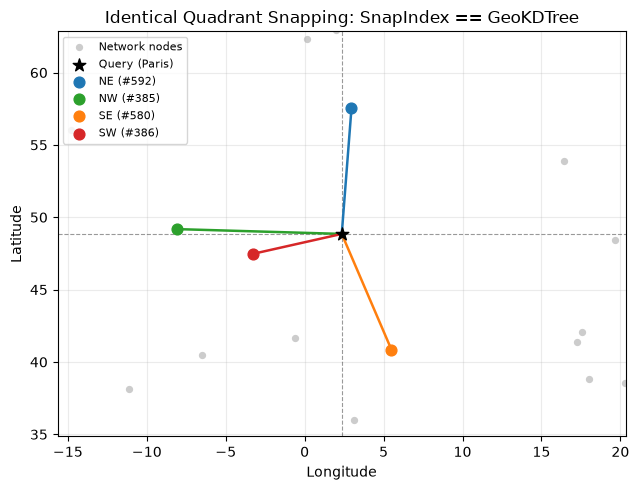

In [7]:
q_paris = [48.85, 2.35]
snap_quads = snap.closest_idx_per_quadrant(q_paris)
kd_quads = kdtree.closest_idx_per_quadrant(q_paris)
assert snap_quads == kd_quads

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(
    [p[1] for p in ordered_points],
    [p[0] for p in ordered_points],
    s=18,
    color="#cccccc",
    label="Network nodes",
)
ax.scatter([q_paris[1]], [q_paris[0]], s=90, color="black", marker="*", zorder=5, label="Query (Paris)")
ax.axvline(q_paris[1], color="black", linestyle="--", linewidth=0.8, alpha=0.4)
ax.axhline(q_paris[0], color="black", linestyle="--", linewidth=0.8, alpha=0.4)

colors = {"ne": "#1f77b4", "nw": "#2ca02c", "se": "#ff7f0e", "sw": "#d62728"}
for name, idx in snap_quads.items():
    pt = ordered_points[idx]
    ax.plot([q_paris[1], pt[1]], [q_paris[0], pt[0]], color=colors[name], linewidth=1.8)
    ax.scatter([pt[1]], [pt[0]], s=60, color=colors[name], zorder=4, label=f"{name.upper()} (#{idx})")

ax.set_xlim(q_paris[1] - 18, q_paris[1] + 18)
ax.set_ylim(q_paris[0] - 14, q_paris[0] + 14)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Identical Quadrant Snapping: SnapIndex == GeoKDTree")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


### Using Either Index Inside `GeoGraph`

Inside `GeoGraph`, `geo.snap_index` uses `SnapIndex` by default (automatically building an internal Hilbert-sorted wrapper when nodes are unordered), while `geo.geokdtree` creates a `GeoKDTree`. Assigning `geo.snap_index = geo.geokdtree` swaps the spatial index cleanly while keeping routing answers identical.


In [8]:
# Build a simple ring graph connecting our 1,000 Hilbert-ordered points
ring = [{} for _ in ordered_points]
for i in range(len(ordered_points)):
    j = (i + 1) % len(ordered_points)
    d = haversine(ordered_points[i], ordered_points[j])
    ring[i][j] = d
    ring[j][i] = d

geo = GeoGraph(graph=ring, nodes=ordered_points)
origin = {"latitude": 48.85, "longitude": 2.35}
destination = {"latitude": 40.71, "longitude": -74.01}

res_snap = geo.get_shortest_path(origin, destination)

# Swap to GeoKDTree
geo.snap_index = geo.geokdtree
res_kd = geo.get_shortest_path(origin, destination)

assert res_snap == res_kd
print(f"SnapIndex length : {res_snap['length']:,.2f} km")
print(f"GeoKDTree length : {res_kd['length']:,.2f} km")
print("Exact same path  :", res_snap["coordinate_path"] == res_kd["coordinate_path"])


SnapIndex length : 22,280.66 km
GeoKDTree length : 22,280.66 km
Exact same path  : True


## 4. Performance at High Latitudes and the Antimeridian

While both indexes return the same nodes, their pruning behavior diverges sharply for **`closest_idx_per_quadrant`** (the default snapping mode used by `GeoGraph.get_shortest_path`):

- **`GeoKDTree`** splits space only along 3D `(x, y, z)` planes. Only `z` matches latitude (`North`/`South`); longitude (`East`/`West`) has no axis-aligned split plane in `(x, y, z)`. When a quadrant is empty (above the northernmost road, below the southernmost point) or separated across the `±180°` antimeridian, `GeoKDTree` cannot prune East/West subtrees using longitude bounds and ends up exploring many more nodes.
- **`SnapIndex`** stores explicit `(min_lat, max_lat, min_lon, max_lon)` bounds (`wrap180`-aware) alongside 3D `(x, y, z)` boxes on every group, so unreachable or empty quadrants are skipped immediately.

Let's measure this on a simple 100,000-point Earth-like dataset (`lat` in `[-55°, 72°]` across the Americas and Afro-Eurasia/Asia, leaving the polar caps and open mid-Pacific empty—just like global road networks).


In [9]:
rng_bench = random.Random(42)
land_points = []
while len(land_points) < 100_000:
    lat = rng_bench.uniform(-55, 72)
    lon = rng_bench.uniform(-130, 145)
    if -35 < lon < -15:
        continue  # leave mid-Atlantic gap
    land_points.append([lat, lon])

land_ordered = [land_points[i] for i in hilbert_order(land_points)]

t0 = time.perf_counter()
snap_100k = SnapIndex(land_ordered)
snap_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
kd_100k = GeoKDTree(land_ordered)
kd_build_ms = (time.perf_counter() - t0) * 1000

print(
    f"Build time (100k points) -> SnapIndex: {snap_build_ms:.1f} ms | "
    f"GeoKDTree: {kd_build_ms:.1f} ms ({kd_build_ms / snap_build_ms:.1f}x slower)"
)


Build time (100k points) -> SnapIndex: 30.8 ms | GeoKDTree: 218.4 ms (7.1x slower)


In [10]:
def avg_query_us(index, queries, method, repeat=5):
    fn = getattr(index, method)
    for q in queries[:10]:
        fn(q)
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        for q in queries:
            fn(q)
        best = min(best, (time.perf_counter() - t0) * 1e6 / len(queries))
    return best


zones = {
    "Mid-latitude\n(Europe 45–52°N)": [
        [rng_bench.uniform(45, 52), rng_bench.uniform(0, 10)] for _ in range(200)
    ],
    "High-lat North\n(Arctic 78–88°N)": [
        [rng_bench.uniform(78, 88), rng_bench.uniform(-180, 180)] for _ in range(200)
    ],
    "High-lat South\n(Antarctic 78–88°S)": [
        [rng_bench.uniform(-88, -78), rng_bench.uniform(-180, 180)] for _ in range(200)
    ],
    "Antimeridian\n(Pacific ±175–180°)": [
        [rng_bench.uniform(-20, 20), rng_bench.choice([-1, 1]) * rng_bench.uniform(175, 180)]
        for _ in range(200)
    ],
}

results = []
for name, qs in zones.items():
    sc = avg_query_us(snap_100k, qs, "closest_idx")
    kc = avg_query_us(kd_100k, qs, "closest_idx")
    sq = avg_query_us(snap_100k, qs, "closest_idx_per_quadrant")
    kq = avg_query_us(kd_100k, qs, "closest_idx_per_quadrant")
    results.append((name, sc, kc, sq, kq))
    label = name.replace("\n", " ")
    print(
        f"{label:38s} | closest: Snap {sc:5.1f} us, KD {kc:5.1f} us "
        f"| quadrant: Snap {sq:5.1f} us, KD {kq:6.1f} us ({kq / sq:4.1f}x)"
    )


Mid-latitude (Europe 45–52°N)          | closest: Snap   1.9 us, KD   0.7 us | quadrant: Snap  10.8 us, KD    2.6 us ( 0.2x)
High-lat North (Arctic 78–88°N)        | closest: Snap   3.0 us, KD   7.5 us | quadrant: Snap  12.2 us, KD   34.7 us ( 2.8x)


High-lat South (Antarctic 78–88°S)     | closest: Snap   3.7 us, KD   4.3 us | quadrant: Snap  13.5 us, KD  201.5 us (14.9x)


Antimeridian (Pacific ±175–180°)       | closest: Snap   2.3 us, KD   2.5 us | quadrant: Snap  16.7 us, KD  255.9 us (15.3x)


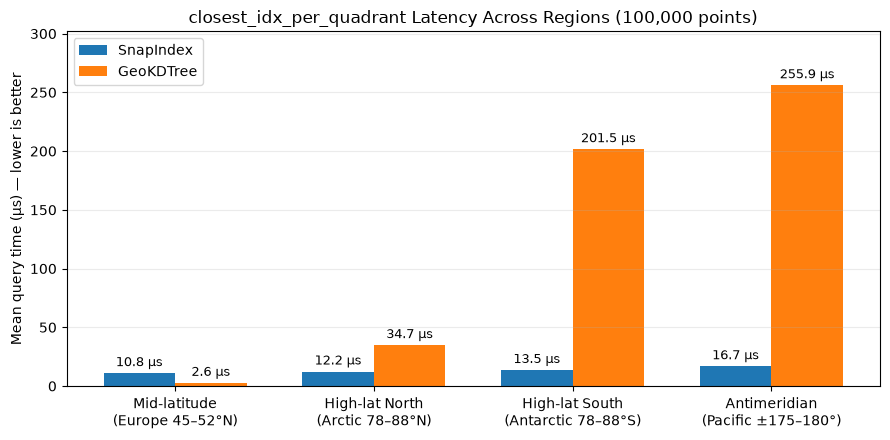

In [11]:
labels = [r[0] for r in results]
snap_quad_us = [r[3] for r in results]
kd_quad_us = [r[4] for r in results]

x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.5))
bars_s = ax.bar([i - width / 2 for i in x], snap_quad_us, width, label="SnapIndex", color="#1f77b4")
bars_k = ax.bar([i + width / 2 for i in x], kd_quad_us, width, label="GeoKDTree", color="#ff7f0e")

ax.bar_label(bars_s, fmt="%.1f µs", padding=3, fontsize=9)
ax.bar_label(bars_k, fmt="%.1f µs", padding=3, fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel("Mean query time (µs) — lower is better")
ax.set_title("closest_idx_per_quadrant Latency Across Regions (100,000 points)")
ax.set_ylim(0, max(kd_quad_us) * 1.18)
ax.legend()
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### Summary

- **In dense mid-latitudes** (`Europe`), all four quadrants find nearby points right away, so both indexes run within a few microseconds per query (`GeoKDTree` is slightly faster on `closest_idx` and mid-latitude quadrants).
- **At high latitudes and across the antimeridian**, some quadrants are empty or wrap across `±180°`: `SnapIndex` stays fast thanks to its explicit latitude/longitude bounding boxes, while `GeoKDTree` has to visit many more subtrees (several times slower in the chart above, and even more on large global road networks).
- **Build & memory**: `SnapIndex` constructs faster on coordinate arrays than `GeoKDTree`, and can read `int32` coordinates from `.scgraph` network files directly in place with zero copies.
